# Embeddings: Teoría, Concepto y Visualización con **Ollama**

Este cuaderno es una clase completa sobre **embeddings** (representaciones vectoriales de texto) usando **Ollama** como motor local.

### ¿Qué encontrarás aquí?

| Sección | Contenido |
|---------|-----------|
| 1 | Fundamentos teóricos: ¿qué es un embedding? |
| 2 | El espacio semántico y la hipótesis distribucional |
| 3 | Obteniendo embeddings desde Ollama (`/api/embeddings`) |
| 4 | Explorando y entendiendo los vectores numéricamente |
| 5 | Métricas de similitud: coseno, euclidiana, producto punto |
| 6 | **Visualización 2D/3D con PCA** |
| 7 | **Mapas de calor (heatmaps) de similitud** |
| 8 | Analogías semánticas (rey - hombre + mujer = reina) |
| 9 | Búsqueda semántica avanzada |
| 10 | Clustering y agrupación de documentos |
| 11 | **PCA vs t‑SNE vs UMAP** — comparación visual |
| 12 | Frases cortas vs documentos largos |
| 13 | Aplicaciones reales y referencias |

> **Requisitos:** Ollama corriendo localmente. Instala dependencias con `pip install -r requirements.txt`.

---
## 0. Setup e imports

In [1]:
import json
import time
import math
import os
from typing import List, Dict, Any, Tuple

import requests
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.colors import Normalize

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.cluster import KMeans

np.set_printoptions(precision=4, suppress=True)

%matplotlib inline
plt.rcParams.update({
    'figure.figsize': (10, 6),
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'font.size': 11,
})

OLLAMA_HOST = os.getenv("OLLAMA_HOST", "http://localhost:11434")
print(f"✓ Host de Ollama: {OLLAMA_HOST}")

✓ Host de Ollama: http://localhost:11434


---
## 1. Fundamentos teóricos: ¿Qué es un embedding?

### Definición conceptual

Un **embedding** es una representación numérica densa de un objeto (palabra, frase, documento, imagen...) en un espacio vectorial continuo de dimensión fija.

$$\text{texto} \xrightarrow{\text{modelo}} \vec{v} \in \mathbb{R}^d$$

**Ejemplo:** la palabra *"perro"* se transforma en un vector de, digamos, 4096 números:

$$\text{perro} \rightarrow [0.023, -0.451, 0.891, \dots, -0.112]$$

### La intuición clave: el espacio semántico

Imagina un espacio donde:
- Palabras con significado similar están **cerca** (ej. *perro* y *canino*).
- Palabras de categorías distintas están en **regiones diferentes** (ej. *animales* vs *tecnología*).
- Las **direcciones** codifican relaciones semánticas (ej. la dirección de *masculino → femenino*).

### Hipótesis distribucional (Firth, 1957)

> *"You shall know a word by the company it keeps."*

Las palabras que aparecen en contextos similares tienen significados similares. Los embeddings capturan precisamente esto.

---
## 2. Funciones auxiliares para interactuar con Ollama

In [2]:
def check_ollama(host: str = OLLAMA_HOST) -> Dict[str, Any]:
    """Verifica que Ollama esté corriendo y devuelve los modelos disponibles."""
    try:
        r = requests.get(f"{host}/api/tags", timeout=10)
        r.raise_for_status()
        return {"ok": True, "models": r.json().get("models", [])}
    except Exception as e:
        return {"ok": False, "error": str(e)}


def get_embedding(text: str, model: str, host: str = OLLAMA_HOST) -> List[float]:
    """Obtiene el embedding de un texto usando la API de Ollama."""
    url = f"{host}/api/embeddings"
    r = requests.post(url, json={"model": model, "prompt": text}, timeout=600)
    r.raise_for_status()
    return r.json()["embedding"]


def get_embeddings(texts: List[str], model: str, host: str = OLLAMA_HOST) -> List[List[float]]:
    """Obtiene embeddings para una lista de textos."""
    embeddings = []
    for i, t in enumerate(texts):
        vec = get_embedding(t, model, host)
        embeddings.append(vec)
        if (i + 1) % 5 == 0:
            print(f"  Procesados {i + 1}/{len(texts)} textos...")
    return embeddings


def cosine_sim(a: List[float], b: List[float]) -> float:
    """Calcula la similitud del coseno entre dos vectores."""
    if not a or not b or len(a) != len(b):
        return -1.0
    a_arr, b_arr = np.array(a), np.array(b)
    return float(np.dot(a_arr, b_arr) / (np.linalg.norm(a_arr) * np.linalg.norm(b_arr) + 1e-9))


def euclidean_dist(a: List[float], b: List[float]) -> float:
    """Distancia euclidiana entre dos vectores."""
    return float(np.linalg.norm(np.array(a) - np.array(b)))


# Verificar que Ollama está arriba
status = check_ollama()
if status["ok"]:
    model_names = [m["name"] for m in status["models"]]
    print(f"✓ Ollama activo. {len(model_names)} modelo(s) disponible(s):")
    for name in model_names:
        print(f"    • {name}")
else:
    print(f"✗ Error: {status['error']}")
    model_names = []

✓ Ollama activo. 2 modelo(s) disponible(s):
    • llama3:latest
    • nomic-embed-text:latest


### Selección del modelo para embeddings

No todos los modelos de Ollama soportan embeddings. Modelos recomendados:

| Modelo | Dimensión | Especialidad |
|--------|-----------|-------------|
| `nomic-embed-text-v2-moe` | 768 | Embeddings multilingües de alta calidad (recomendado) |
| `nomic-embed-text` | 768 | Embeddings generales (inglés) |
| `bge-m3` | 1024 | Embeddings multilingües, buen retrieval |
| `mxbai-embed-large` | 1024 | Embeddings de alta calidad |
| `snowflake-arctic-embed` | 1024 | Optimizado para búsqueda |
| `all-minilm` | 384 | Rápido y ligero |
| `llama3` / `mistral` | ~4096 | LLMs que también generan embeddings |

El código detecta automáticamente el primer modelo disponible que soporte embeddings. Se prioriza `nomic-embed-text-v2-moe` por su mejor separación semántica en español.

In [3]:
EMBED_MODELS = ["nomic-embed-text-v2-moe", "nomic-embed-text", "mxbai-embed-large",
                 "bge-m3", "snowflake-arctic-embed", "all-minilm",
                 "llama3", "mistral", "phi3", "qwen2.5"]

embed_model = None
for candidate in EMBED_MODELS:
    # Buscar coincidencia parcial (ej. "nomic-embed-text:latest" contiene "nomic-embed-text")
    if any(candidate in m for m in model_names):
        embed_model = candidate
        print(f"✓ Modelo para embeddings seleccionado: {embed_model}")
        break

if embed_model is None and len(model_names) > 0:
    embed_model = model_names[0]
    print(f"⚠ Usando primer modelo disponible (puede no soportar embeddings): {embed_model}")
elif embed_model is None:
    print("⚠ No hay modelos disponibles. Descarga uno con: ollama pull nomic-embed-text")
    print("  Luego reinicia el kernel.")
    embed_model = "nomic-embed-text"

✓ Modelo para embeddings seleccionado: nomic-embed-text


---
## 3. Obteniendo nuestros primeros embeddings

In [5]:
textos_demo = [
    "Un perro juega alegremente en el parque junto a su dueño.",
    "Un can corre feliz por el jardín junto a su amo.",
    "La inteligencia artificial transforma la industria moderna.",
    "El aprendizaje automático revoluciona la industria moderna.",
    "La pizza es un plato italiano muy popular en todo el mundo.",
    "La pasta es una comida italiana muy popular en todo el mundo.",
    "Los planetas orbitan alrededor del sol en el sistema solar.",
    "Los astrónomos estudian los cuerpos celestes del universo.",
]

print(f"Obteniendo embeddings con modelo: {embed_model}")
try:
    embeddings_demo = get_embeddings(textos_demo, model=embed_model)
    dim = len(embeddings_demo[0])
    print(f"\n✓ {len(embeddings_demo)} embeddings generados. Dimensión: {dim}")
except Exception as e:
    print(f"\n✗ Error: {e}")
    print("Asegúrate de tener un modelo que soporte embeddings.")
    print("Ejecuta en terminal: ollama pull nomic-embed-text")
    embeddings_demo = None
    dim = 0

Obteniendo embeddings con modelo: nomic-embed-text-v2-moe
  Procesados 5/8 textos...

✓ 8 embeddings generados. Dimensión: 768


---
## 4. ¿Cómo se ve un embedding por dentro?

Un embedding es simplemente un **array de números**. Veamos sus propiedades:

Texto: "Un perro juega alegremente en el parque junto a su dueño."

Vector (primeros 20 valores de 768):
[ 0.2596  0.6076  0.1511  0.4864  0.0071 -0.2476  0.1352 -0.3402  0.5374
 -0.226   1.1004  0.3057  0.4808 -1.019  -0.1189  0.0331  0.1518 -0.1612
 -0.2353  0.2401]

Estadísticas del vector:
  Media:     -0.002607
  Desv. std: 0.492478
  Mínimo:    -1.699337
  Máximo:    1.667535
  Norma L2:  13.6481

Histograma de valores:



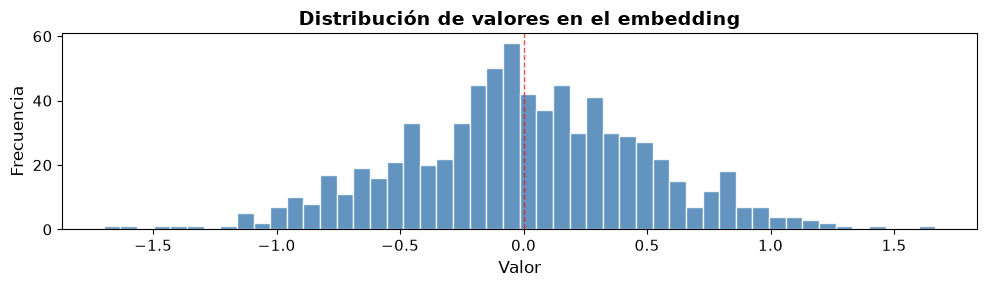

In [6]:
if embeddings_demo:
    v = np.array(embeddings_demo[0])
    print(f"Texto: \"{textos_demo[0]}\"")
    print(f"\nVector (primeros 20 valores de {dim}):")
    print(v[:20])
    print(f"\nEstadísticas del vector:")
    print(f"  Media:     {v.mean():.6f}")
    print(f"  Desv. std: {v.std():.6f}")
    print(f"  Mínimo:    {v.min():.6f}")
    print(f"  Máximo:    {v.max():.6f}")
    print(f"  Norma L2:  {np.linalg.norm(v):.4f}")
    print(f"\nHistograma de valores:\n")
    fig, ax = plt.subplots(figsize=(10, 3))
    ax.hist(v, bins=50, color='steelblue', edgecolor='white', alpha=0.85)
    ax.set_title('Distribución de valores en el embedding', fontweight='bold')
    ax.set_xlabel('Valor')
    ax.set_ylabel('Frecuencia')
    ax.axvline(0, color='red', linestyle='--', linewidth=1, alpha=0.7)
    plt.tight_layout()
    plt.show()
else:
    print("No hay embeddings para analizar. Verifica la celda anterior.")

**Observaciones:**
- Los valores están centrados alrededor de 0 (media ≈ 0).
- La distribución suele ser aproximadamente normal.
- Cada dimensión contribuye a la posición en el **espacio semántico**.
- La **dirección** del vector (no su magnitud) es lo que codifica el significado.

> **Dato clave:** En embeddings normalizados, la similitud del coseno equivale al producto punto. Muchos modelos de embeddings ya normalizan los vectores a longitud 1.

---
## 5. Métricas de similitud: teoría y práctica

### 5.1 Similitud del coseno

Mide el **ángulo** entre dos vectores, ignorando su magnitud.

$$\text{cosine}(\vec{a}, \vec{b}) = \frac{\vec{a} \cdot \vec{b}}{\|\vec{a}\| \cdot \|\vec{b}\|}$$

- Rango: $[-1, 1]$ (en embeddings reales suele ser $[0, 1]$).
- **1.0** = vectores paralelos, misma dirección (significado idéntico).
- **0.0** = vectores ortogonales (sin relación semántica).
- **-1.0** = vectores opuestos (significados opuestos, raro en la práctica).

### 5.2 Distancia euclidiana

Mide la **distancia en línea recta** entre dos puntos.

$$d(\vec{a}, \vec{b}) = \sqrt{\sum_{i=1}^{d} (a_i - b_i)^2}$$

- Menos usada en embeddings porque es sensible a la magnitud.

### 5.3 Producto punto (dot product)

$$\vec{a} \cdot \vec{b} = \sum_{i=1}^{d} a_i \cdot b_i$$

- Si los vectores están normalizados, equivale a la similitud del coseno.

In [7]:
if embeddings_demo:
    # Pares dentro de la misma categoría (deberían ser SIMILARES)
    pares_similares = [
        (0, 1, "perro vs can"),
        (2, 3, "IA vs aprendizaje automático"),
        (4, 5, "pizza vs pasta"),
        (6, 7, "planetas vs astronomía"),
    ]
    # Pares de categorías distintas (deberían ser DIFERENTES)
    pares_diferentes = [
        (0, 4, "perro vs pizza"),
        (0, 6, "perro vs planetas"),
        (2, 4, "IA vs pizza"),
        (2, 6, "IA vs planetas"),
    ]

    filas = []
    for i, j, desc in pares_similares:
        filas.append((cosine_sim(embeddings_demo[i], embeddings_demo[j]),
                       euclidean_dist(embeddings_demo[i], embeddings_demo[j]),
                       float(np.dot(embeddings_demo[i], embeddings_demo[j])),
                       desc, "SIMILAR"))
    for i, j, desc in pares_diferentes:
        filas.append((cosine_sim(embeddings_demo[i], embeddings_demo[j]),
                       euclidean_dist(embeddings_demo[i], embeddings_demo[j]),
                       float(np.dot(embeddings_demo[i], embeddings_demo[j])),
                       desc, "DIFERENTE"))

    # Ordenar por similitud del coseno descendente
    filas.sort(key=lambda f: -f[0])

    print(f"{'Par':<35} {'Tipo':<10} {'Cos':>8} {'EucDist':>9} {'Dot':>10}")
    print("-" * 75)
    for cos, euc, dot, desc, tipo in filas:
        print(f"{desc:<35} {tipo:<10} {cos:>8.4f} {euc:>9.4f} {dot:>10.4f}")

    cos_sim = [f[0] for f in filas if f[4] == "SIMILAR"]
    cos_dif = [f[0] for f in filas if f[4] == "DIFERENTE"]
    print("\n✓ Resumen:")
    print(f"  Coseno medio pares SIMILARES:   {np.mean(cos_sim):.4f}")
    print(f"  Coseno medio pares DIFERENTES:  {np.mean(cos_dif):.4f}")
    print(f"  Margen de separación:           {np.mean(cos_sim) - np.mean(cos_dif):.4f}")
    print("\n→ Los pares SIMILARES encabezan el ranking (coseno alto, distancia baja).")
else:
    print("No hay embeddings para comparar.")

Par                                 Tipo            Cos   EucDist        Dot
---------------------------------------------------------------------------
IA vs aprendizaje automático        SIMILAR      0.8272    8.5972   176.4248
pizza vs pasta                      SIMILAR      0.8009    8.8420   157.1986
perro vs can                        SIMILAR      0.6356   11.8494   122.2894
planetas vs astronomía              SIMILAR      0.5480   13.6960   113.5649
perro vs planetas                   DIFERENTE    0.2562   17.2653    51.1669
perro vs pizza                      DIFERENTE    0.2479   16.9318    47.2423
IA vs pizza                         DIFERENTE    0.2350   17.5306    47.1868
IA vs planetas                      DIFERENTE    0.1769   18.6145    37.2247

✓ Resumen:
  Coseno medio pares SIMILARES:   0.7029
  Coseno medio pares DIFERENTES:  0.2290
  Margen de separación:           0.4739

→ Los pares SIMILARES encabezan el ranking (coseno alto, distancia baja).


### 5.4 Ilustración visual: coseno vs euclidiana

La siguiente figura muestra dos vectores en 2D y explica por qué el coseno es preferido para tareas semánticas:

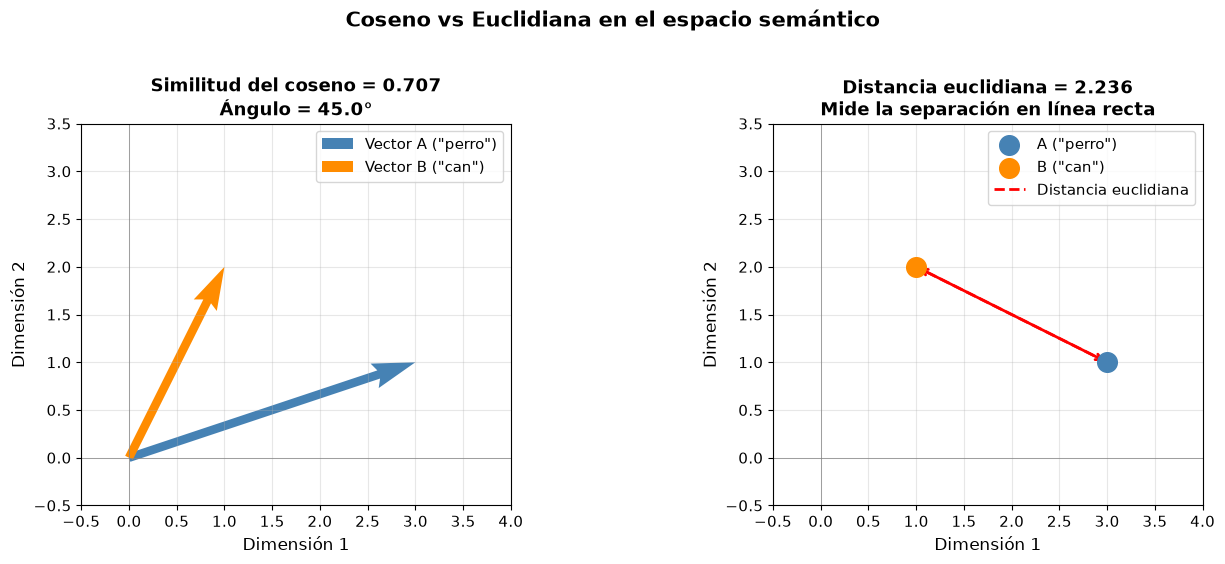


Clave: El coseno mide DIRECCIÓN (significado). La euclidiana mide DISTANCIA (magnitud).
En embeddings: nos importa la dirección → usamos coseno.


In [8]:
def plot_distance_demo():
    """Ilustra la diferencia conceptual entre coseno y distancia euclidiana."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

    # --- Panel A: Coseno ---
    ax = axes[0]
    origin = np.array([0, 0])
    a = np.array([3, 1])
    b = np.array([1, 2])

    ax.quiver(*origin, *a, angles='xy', scale_units='xy', scale=1,
              color='steelblue', width=0.02, label='Vector A ("perro")')
    ax.quiver(*origin, *b, angles='xy', scale_units='xy', scale=1,
              color='darkorange', width=0.02, label='Vector B ("can")')

    cos_val = np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))
    angle = np.arccos(cos_val)
    ax.set_title(f'Similitud del coseno = {cos_val:.3f}\nÁngulo = {np.degrees(angle):.1f}°',
                 fontweight='bold', fontsize=13)
    ax.set_xlim(-0.5, 4)
    ax.set_ylim(-0.5, 3.5)
    ax.set_xlabel('Dimensión 1')
    ax.set_ylabel('Dimensión 2')
    ax.legend(loc='upper right')
    ax.axhline(0, color='gray', linewidth=0.5)
    ax.axvline(0, color='gray', linewidth=0.5)
    ax.grid(True, alpha=0.3)
    ax.set_aspect('equal')

    # --- Panel B: Euclidiana ---
    ax = axes[1]
    ax.scatter(*a, s=200, color='steelblue', zorder=5, label='A ("perro")')
    ax.scatter(*b, s=200, color='darkorange', zorder=5, label='B ("can")')
    ax.plot([a[0], b[0]], [a[1], b[1]], 'r--', linewidth=2, label=f'Distancia euclidiana')
    ax.annotate('', xy=b, xytext=a, arrowprops=dict(arrowstyle='<->', color='red', lw=2))

    dist = np.linalg.norm(a - b)
    ax.set_title(f'Distancia euclidiana = {dist:.3f}\nMide la separación en línea recta',
                 fontweight='bold', fontsize=13)
    ax.set_xlim(-0.5, 4)
    ax.set_ylim(-0.5, 3.5)
    ax.set_xlabel('Dimensión 1')
    ax.set_ylabel('Dimensión 2')
    ax.legend(loc='upper right')
    ax.axhline(0, color='gray', linewidth=0.5)
    ax.axvline(0, color='gray', linewidth=0.5)
    ax.grid(True, alpha=0.3)
    ax.set_aspect('equal')

    plt.suptitle('Coseno vs Euclidiana en el espacio semántico', fontsize=15,
                 fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

plot_distance_demo()
print("\nClave: El coseno mide DIRECCIÓN (significado). La euclidiana mide DISTANCIA (magnitud).")
print("En embeddings: nos importa la dirección → usamos coseno.")

---
## 6. Visualización 2D con PCA

**PCA** (Análisis de Componentes Principales) reduce la dimensionalidad proyectando los datos a las direcciones de máxima varianza. Ideal para una primera exploración visual.

Varianza explicada: PC1=28.82%, PC2=25.50%
Total: 54.32%

   → En alta dimensionalidad, 2 componentes explican poco, pero suficiente para visualizar patrones.


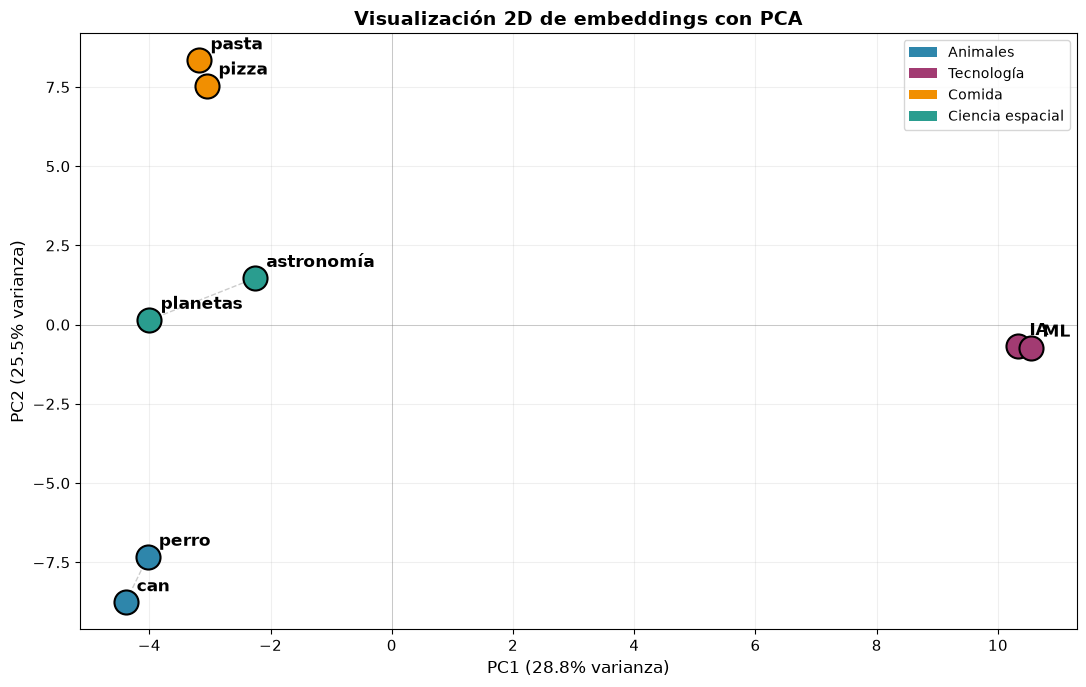

In [9]:
if embeddings_demo:
    X = np.array(embeddings_demo)

    # Reducción a 2D con PCA
    pca = PCA(n_components=2, random_state=42)
    X_pca = pca.fit_transform(X)

    print(f"Varianza explicada: PC1={pca.explained_variance_ratio_[0]:.2%}, "
          f"PC2={pca.explained_variance_ratio_[1]:.2%}")
    print(f"Total: {pca.explained_variance_ratio_.sum():.2%}")
    print("\n   → En alta dimensionalidad, 2 componentes explican poco, pero "
          "suficiente para visualizar patrones.")

    # Etiquetas cortas para graficar
    labels = [
        "perro", "can", "IA", "ML",
        "pizza", "pasta", "planetas", "astronomía"
    ]
    colors = ['#2E86AB', '#2E86AB', '#A23B72', '#A23B72',
              '#F18F01', '#F18F01', '#2A9D8F', '#2A9D8F']

    fig, ax = plt.subplots(figsize=(11, 7))
    for i in range(len(X_pca)):
        ax.scatter(X_pca[i, 0], X_pca[i, 1], c=colors[i], s=300, edgecolors='black',
                   linewidth=1.5, zorder=5)
        ax.annotate(labels[i], (X_pca[i, 0], X_pca[i, 1]),
                    textcoords="offset points", xytext=(8, 8),
                    fontsize=12, fontweight='bold')

    # Líneas entre pares semánticos
    pairs = [(0, 1), (2, 3), (4, 5), (6, 7)]
    for i, j in pairs:
        ax.plot([X_pca[i, 0], X_pca[j, 0]], [X_pca[i, 1], X_pca[j, 1]],
                'gray', linewidth=1, alpha=0.4, linestyle='--')

    ax.set_title('Visualización 2D de embeddings con PCA', fontweight='bold', fontsize=14)
    ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} varianza)')
    ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} varianza)')
    ax.axhline(0, color='gray', linewidth=0.5, alpha=0.5)
    ax.axvline(0, color='gray', linewidth=0.5, alpha=0.5)
    ax.grid(True, alpha=0.2)

    # Leyenda de categorías
    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor='#2E86AB', label='Animales'),
        Patch(facecolor='#A23B72', label='Tecnología'),
        Patch(facecolor='#F18F01', label='Comida'),
        Patch(facecolor='#2A9D8F', label='Ciencia espacial'),
    ]
    ax.legend(handles=legend_elements, loc='upper right', fontsize=10)
    plt.tight_layout()
    plt.show()
else:
    print("No hay embeddings para visualizar.")

**Interpretación:**
- Conceptos de la misma categoría se agrupan espacialmente.
- Categorías diferentes ocupan regiones distintas.
- Esto ocurre **sin que le hayamos dicho al modelo** cuáles son las categorías: el embedding las infiere del lenguaje.

---
## 7. Visualización 3D con PCA

Añadir una tercera dimensión revela más estructura:

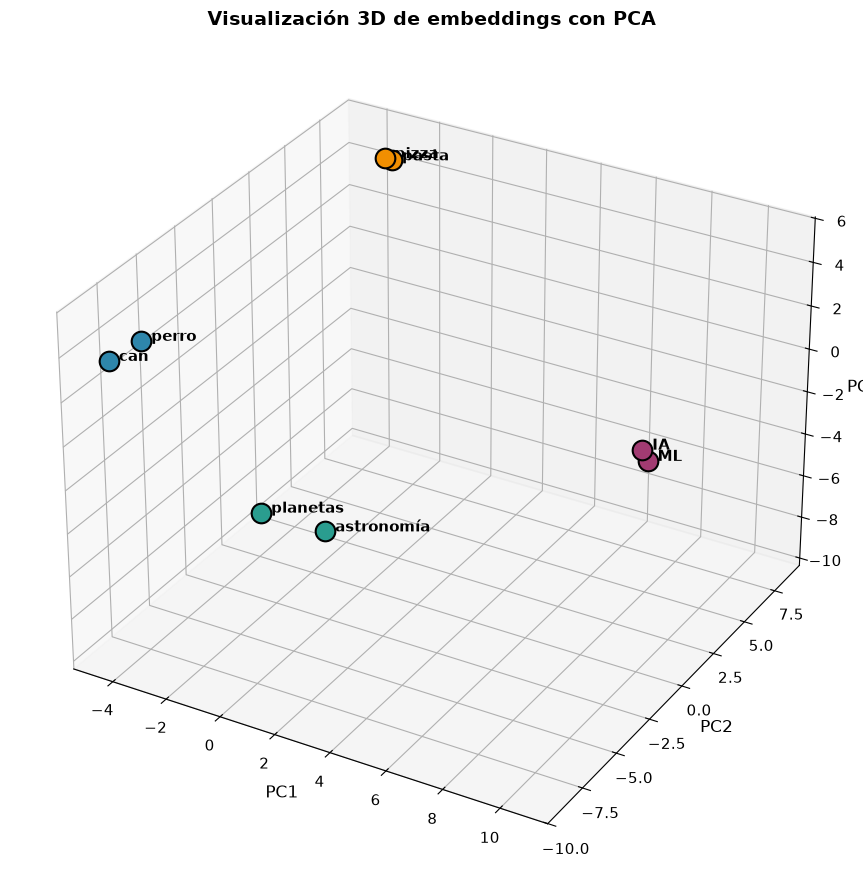

Varianza explicada 3D: 76.78%


In [10]:
if embeddings_demo:
    from mpl_toolkits.mplot3d import Axes3D

    pca3 = PCA(n_components=3, random_state=42)
    X_pca3 = pca3.fit_transform(X)

    fig = plt.figure(figsize=(12, 9))
    ax = fig.add_subplot(111, projection='3d')

    for i in range(len(X_pca3)):
        ax.scatter(X_pca3[i, 0], X_pca3[i, 1], X_pca3[i, 2],
                   c=colors[i], s=200, edgecolors='black', linewidth=1.5)
        ax.text(X_pca3[i, 0], X_pca3[i, 1], X_pca3[i, 2],
                f"  {labels[i]}", fontsize=11, fontweight='bold')

    ax.set_title('Visualización 3D de embeddings con PCA', fontweight='bold', fontsize=14)
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
    ax.set_zlabel('PC3')
    plt.tight_layout()
    plt.show()
    print(f"Varianza explicada 3D: {pca3.explained_variance_ratio_.sum():.2%}")
else:
    print("No hay embeddings para visualizar 3D.")

---
## 8. Mapa de calor de similitud (Heatmap)

Una matriz de similitud muestra de un vistazo cómo se relacionan todos los textos entre sí.

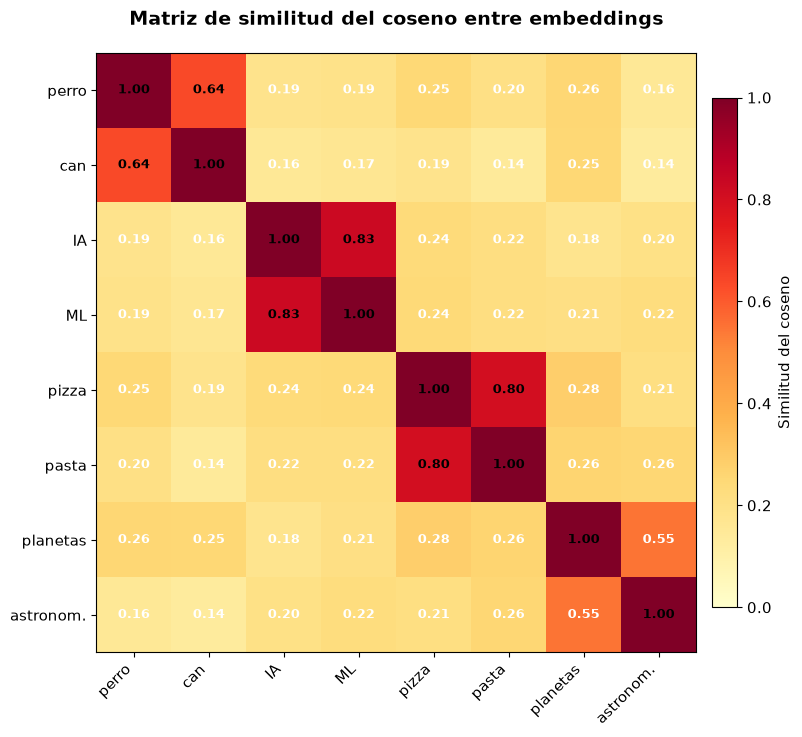


✓ Bloques cálidos (rojo) = alta similitud = misma categoría semántica.
✓ Bloques fríos (amarillo) = baja similitud = categorías diferentes.
✓ La diagonal es siempre 1.0 (cada texto consigo mismo).


In [11]:
if embeddings_demo:
    n = len(embeddings_demo)
    sim_matrix = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            sim_matrix[i, j] = cosine_sim(embeddings_demo[i], embeddings_demo[j])

    fig, ax = plt.subplots(figsize=(9, 7.5))
    im = ax.imshow(sim_matrix, cmap='YlOrRd', vmin=0.0, vmax=1.0, aspect='equal')

    short_labels = ["perro", "can", "IA", "ML", "pizza", "pasta", "planetas", "astronom."]
    ax.set_xticks(range(n))
    ax.set_yticks(range(n))
    ax.set_xticklabels(short_labels, rotation=45, ha='right', fontsize=11)
    ax.set_yticklabels(short_labels, fontsize=11)

    # Anotar valores
    for i in range(n):
        for j in range(n):
            ax.text(j, i, f"{sim_matrix[i, j]:.2f}", ha='center', va='center',
                    fontsize=9, fontweight='bold',
                    color='white' if sim_matrix[i, j] < 0.6 else 'black')

    ax.set_title('Matriz de similitud del coseno entre embeddings',
                 fontweight='bold', fontsize=14, pad=20)
    cbar = plt.colorbar(im, ax=ax, shrink=0.85, pad=0.02)
    cbar.set_label('Similitud del coseno', fontsize=11)
    plt.tight_layout()
    plt.show()

    print("\n✓ Bloques cálidos (rojo) = alta similitud = misma categoría semántica.")
    print("✓ Bloques fríos (amarillo) = baja similitud = categorías diferentes.")
    print("✓ La diagonal es siempre 1.0 (cada texto consigo mismo).")
else:
    print("No hay embeddings para el heatmap.")

---
## 9. Analogías semánticas

Una de las propiedades más fascinantes de los embeddings es que las **operaciones vectoriales** capturan relaciones semánticas:

$$\text{rey} - \text{hombre} + \text{mujer} \approx \text{reina}$$

La diferencia $\text{rey} - \text{hombre}$ codifica el concepto de *"realeza"* quitando *"masculinidad"*. Al sumar *"mujer"*, obtenemos *"realeza + feminidad"* ≈ *"reina"*.

Probemos con nuestros propios ejemplos:

In [12]:
if embeddings_demo:
    # Vocabulario rico para evaluar las analogías (se excluyen las palabras de entrada)
    vocabulario = [
        "reina", "princesa", "príncipe", "emperador", "emperatriz", "rey", "duque", "nobleza",
        "hombre", "mujer", "niño", "niña", "varón", "hembra",
        "madrid", "parís", "berlín", "roma", "lisboa", "londres", "tokio",
        "españa", "francia", "alemania", "italia", "portugal", "inglaterra", "japón",
        "perro", "lobo", "gato", "león", "tigre", "zorro", "águila",
        "cachorro", "cría", "salvaje", "doméstico",
    ]
    # Eliminar duplicados conservando el orden
    vocabulario = list(dict.fromkeys(vocabulario))

    print(f"Precomputando embeddings de {len(vocabulario)} palabras del vocabulario...")
    vocab_vecs = {w: np.array(get_embedding(w, embed_model)) for w in vocabulario}

    # (a, b, c, target_esperado)  — target=None significa analogía exploratoria
    analogias = [
        ("rey", "hombre", "mujer", "reina"),
        ("madrid", "españa", "francia", "parís"),
        ("madrid", "españa", "alemania", "berlín"),
    ]

    for a, b, c, target in analogias:
        try:
            v_a = np.array(get_embedding(a, embed_model))
            v_b = np.array(get_embedding(b, embed_model))
            v_c = np.array(get_embedding(c, embed_model))
        except Exception as e:
            print(f"  Error con {a}, {b}, {c}: {e}")
            continue

        # Vector resultante: a - b + c
        v_res = v_a - v_b + v_c
        norm_res = np.linalg.norm(v_res)

        # Rankear las palabras del vocabulario (excluyendo a, b, c)
        scored = []
        for w, v_w in vocab_vecs.items():
            if w in (a, b, c):
                continue
            sim = float(np.dot(v_res, v_w) / (norm_res * np.linalg.norm(v_w) + 1e-9))
            scored.append((w, sim))
        scored.sort(key=lambda x: -x[1])

        print(f"\n  {a} − {b} + {c}  →  (objetivo esperado: '{target}')")
        for rank, (w, sim) in enumerate(scored[:5], 1):
            marca = "  ◀ TARGET ✓" if w == target else ""
            print(f"     #{rank}  {w:<12} sim={sim:.4f}{marca}")
        acierto = (scored[0][0] == target)
        print(f"     → {'✓ Acierto: el target encabeza el ranking.' if acierto else '✗ El target no fue #1 (común en embeddings de frase).'}")
else:
    print("No hay embedding model disponible.")

Precomputando embeddings de 39 palabras del vocabulario...

  rey − hombre + mujer  →  (objetivo esperado: 'reina')
     #1  reina        sim=0.5880  ◀ TARGET ✓
     #2  emperatriz   sim=0.4472
     #3  princesa     sim=0.4428
     #4  niña         sim=0.3622
     #5  príncipe     sim=0.3584
     → ✓ Acierto: el target encabeza el ranking.

  madrid − españa + francia  →  (objetivo esperado: 'parís')
     #1  parís        sim=0.5107  ◀ TARGET ✓
     #2  roma         sim=0.3593
     #3  londres      sim=0.3403
     #4  berlín       sim=0.3401
     #5  japón        sim=0.3163
     → ✓ Acierto: el target encabeza el ranking.

  madrid − españa + alemania  →  (objetivo esperado: 'berlín')
     #1  berlín       sim=0.4482  ◀ TARGET ✓
     #2  roma         sim=0.3297
     #3  parís        sim=0.2885
     #4  japón        sim=0.2419
     #5  londres      sim=0.2266
     → ✓ Acierto: el target encabeza el ranking.


---
## 10. Búsqueda semántica avanzada

Vamos más allá del mini-RAG básico. Construimos un **buscador semántico** sobre un corpus de documentos, con ranking y visualización.

In [13]:
corpus = [
    "Python es un lenguaje de programación interpretado, de alto nivel y con tipado dinámico.",
    "JavaScript es el lenguaje principal para desarrollo web del lado del cliente.",
    "El aprendizaje profundo (deep learning) utiliza redes neuronales con múltiples capas.",
    "Los transformers revolucionaron el procesamiento de lenguaje natural en 2017.",
    "El sistema solar está compuesto por el sol y ocho planetas que lo orbitan.",
    "La Vía Láctea es la galaxia espiral donde se encuentra nuestro sistema solar.",
    "La Revolución Francesa de 1789 marcó el fin de la monarquía absoluta en Francia.",
    "La Segunda Guerra Mundial duró de 1939 a 1945 y redefinió el orden geopolítico global.",
    "El ADN contiene la información genética de todos los seres vivos.",
    "La fotosíntesis convierte la energía solar en energía química en las plantas.",
    "Kubernetes es una plataforma de orquestación de contenedores de código abierto.",
    "Docker permite empaquetar aplicaciones en contenedores ligeros y portables.",
    "Shakespeare escribió Hamlet, una de las tragedias más famosas de la literatura inglesa.",
    "Cervantes es el autor de Don Quijote, obra cumbre de la literatura en español.",
    "El fútbol es el deporte más popular del mundo con más de 4 mil millones de seguidores.",
]

def build_search_index(corpus: List[str]) -> Tuple[List[str], np.ndarray, List[List[float]]]:
    """Construye un índice de búsqueda semántica."""
    print(f"Indexando {len(corpus)} documentos...")
    vecs = get_embeddings(corpus, model=embed_model)
    return corpus, np.array(vecs), vecs


def semantic_search(query: str, corpus: List[str], vecs: np.ndarray, top_k: int = 5):
    """Busca los documentos más similares semánticamente a la query."""
    qv = np.array(get_embedding(query, embed_model))
    sims = cosine_similarity([qv], vecs)[0]
    top_idx = np.argsort(sims)[::-1][:top_k]
    return [(int(i), float(sims[i]), corpus[i]) for i in top_idx]


print("Construyendo índice de búsqueda...")
try:
    corpus, vecs_matrix, _ = build_search_index(corpus)
    print(f"✓ Índice listo. {vecs_matrix.shape[0]} documentos, dimensión {vecs_matrix.shape[1]}.\n")

    queries = [
        "lenguajes de programación para la web",
        "eventos importantes de la historia europea",
        "tecnología para desplegar aplicaciones en la nube",
        "cómo las plantas transforman la luz en energía",
        "estructuras genéticas de los seres vivos",
    ]

    for q in queries:
        print(f"\n{'='*60}")
        print(f"🔍 Query: \"{q}\"")
        print(f"{'='*60}")
        results = semantic_search(q, corpus, vecs_matrix, top_k=3)
        for rank, (idx, score, doc) in enumerate(results, 1):
            bar = '█' * int(score * 20)
            print(f"  #{rank} [sim={score:.3f}] {bar}")
            print(f"      {doc[:100]}{'...' if len(doc) > 100 else ''}")
except Exception as e:
    print(f"Error en búsqueda semántica: {e}")

Construyendo índice de búsqueda...
Indexando 15 documentos...
  Procesados 5/15 textos...
  Procesados 10/15 textos...
  Procesados 15/15 textos...
✓ Índice listo. 15 documentos, dimensión 768.


🔍 Query: "lenguajes de programación para la web"
  #1 [sim=0.636] ████████████
      JavaScript es el lenguaje principal para desarrollo web del lado del cliente.
  #2 [sim=0.458] █████████
      Python es un lenguaje de programación interpretado, de alto nivel y con tipado dinámico.
  #3 [sim=0.374] ███████
      Kubernetes es una plataforma de orquestación de contenedores de código abierto.

🔍 Query: "eventos importantes de la historia europea"
  #1 [sim=0.393] ███████
      La Segunda Guerra Mundial duró de 1939 a 1945 y redefinió el orden geopolítico global.
  #2 [sim=0.379] ███████
      La Revolución Francesa de 1789 marcó el fin de la monarquía absoluta en Francia.
  #3 [sim=0.314] ██████
      Shakespeare escribió Hamlet, una de las tragedias más famosas de la literatura inglesa.

🔍 Qu

### Visualización del resultado de búsqueda
Veamos gráficamente dónde cae la query respecto a los documentos.

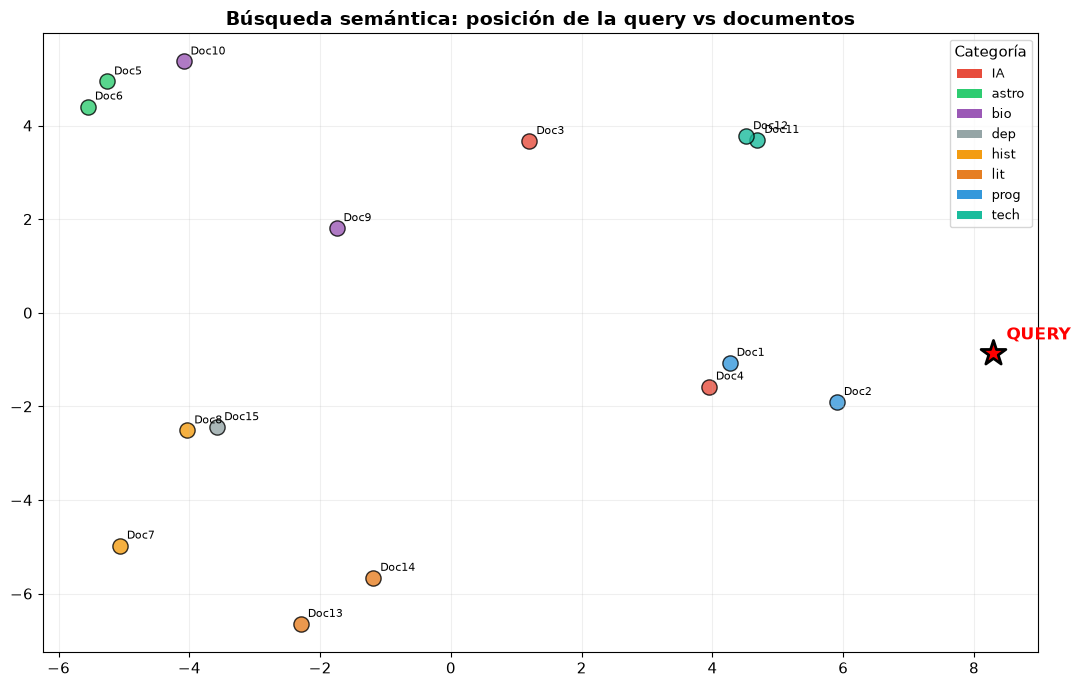

In [14]:
if 'vecs_matrix' in dir():
    qv = np.array(get_embedding("lenguajes de programación", embed_model))
    all_vecs = np.vstack([vecs_matrix, qv])
    pca_search = PCA(n_components=2, random_state=42)
    all_2d = pca_search.fit_transform(all_vecs)

    fig, ax = plt.subplots(figsize=(11, 7))
    temas = ["prog", "prog", "IA", "IA", "astro", "astro",
             "hist", "hist", "bio", "bio", "tech", "tech",
             "lit", "lit", "dep"]
    palette = {
        "prog": "#3498db", "IA": "#e74c3c", "astro": "#2ecc71",
        "hist": "#f39c12", "bio": "#9b59b6", "tech": "#1abc9c",
        "lit": "#e67e22", "dep": "#95a5a6"
    }

    for i in range(len(corpus)):
        ax.scatter(all_2d[i, 0], all_2d[i, 1], c=palette[temas[i]],
                   s=120, edgecolors='black', linewidth=1, alpha=0.8)
        ax.annotate(f"Doc{i+1}", (all_2d[i, 0], all_2d[i, 1]),
                    textcoords="offset points", xytext=(5, 5), fontsize=8)

    # La query destacada
    ax.scatter(all_2d[-1, 0], all_2d[-1, 1], c='red', s=350, marker='*',
               edgecolors='black', linewidth=2, zorder=10, label='Query')
    ax.annotate('QUERY', (all_2d[-1, 0], all_2d[-1, 1]),
                textcoords="offset points", xytext=(10, 10),
                fontsize=12, fontweight='bold', color='red')

    ax.set_title('Búsqueda semántica: posición de la query vs documentos',
                 fontweight='bold', fontsize=14)
    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor=palette[k], label=k) for k in sorted(set(temas))
    ]
    ax.legend(handles=legend_elements, loc='upper right', fontsize=9,
              title='Categoría')
    ax.grid(True, alpha=0.2)
    plt.tight_layout()
    plt.show()
else:
    print("No se ha construido el índice de búsqueda.")

---
## 11. Clustering: agrupando documentos por tema

Usamos **K-Means** sobre los embeddings para descubrir automáticamente grupos temáticos.

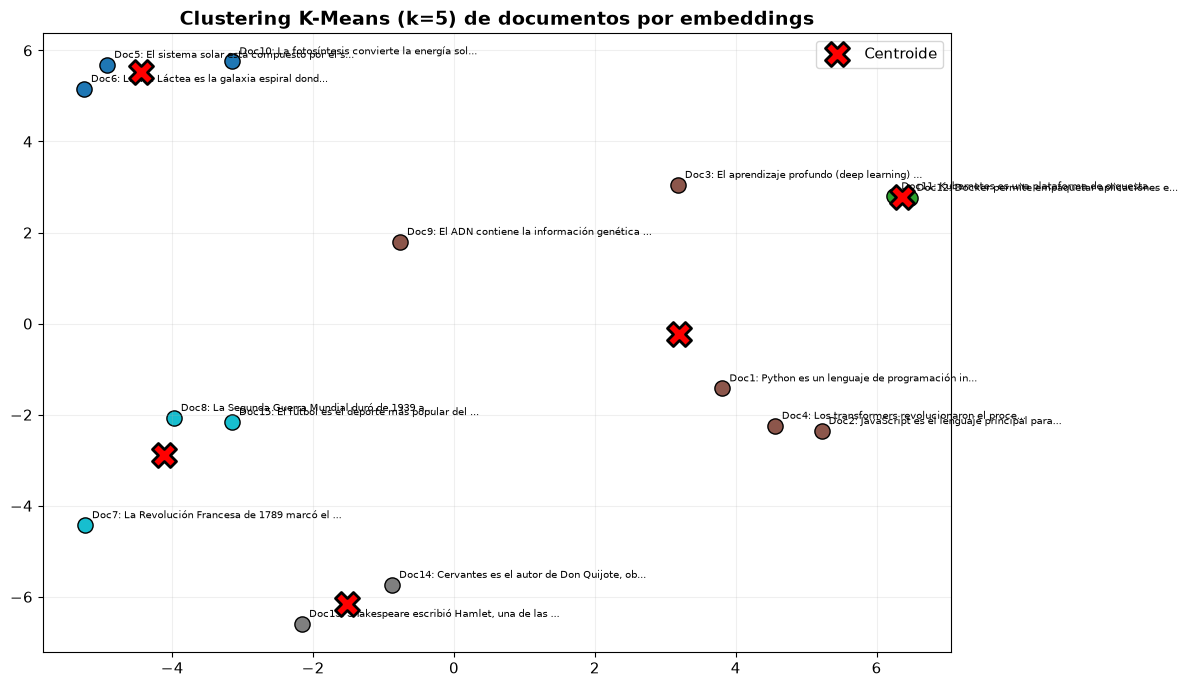


Asignación de documentos a clusters:

  Cluster 0:
    [4] El sistema solar está compuesto por el sol y ocho planetas que lo orbitan....
    [5] La Vía Láctea es la galaxia espiral donde se encuentra nuestro sistema solar....
    [9] La fotosíntesis convierte la energía solar en energía química en las plantas....

  Cluster 1:
    [10] Kubernetes es una plataforma de orquestación de contenedores de código abierto....
    [11] Docker permite empaquetar aplicaciones en contenedores ligeros y portables....

  Cluster 2:
    [0] Python es un lenguaje de programación interpretado, de alto nivel y con tipado dinámico....
    [1] JavaScript es el lenguaje principal para desarrollo web del lado del cliente....
    [2] El aprendizaje profundo (deep learning) utiliza redes neuronales con múltiples capas....
    [3] Los transformers revolucionaron el procesamiento de lenguaje natural en 2017....
    [8] El ADN contiene la información genética de todos los seres vivos....

  Cluster 3:
    [12] S

In [15]:
if 'vecs_matrix' in dir():
    n_clusters = 5
    kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
    clusters = kmeans.fit_predict(vecs_matrix)

    # Reducir para visualizar
    pca_cluster = PCA(n_components=2, random_state=42)
    X_cluster_2d = pca_cluster.fit_transform(vecs_matrix)

    fig, ax = plt.subplots(figsize=(12, 7))
    cluster_colors = cm.tab10(np.linspace(0, 1, n_clusters))

    for i in range(len(corpus)):
        c = cluster_colors[clusters[i]]
        ax.scatter(X_cluster_2d[i, 0], X_cluster_2d[i, 1],
                   c=[c], s=120, edgecolors='black', linewidth=1)
        ax.annotate(f"Doc{i+1}: {corpus[i][:40]}...",
                    (X_cluster_2d[i, 0], X_cluster_2d[i, 1]),
                    textcoords="offset points", xytext=(5, 5), fontsize=7)

    # Centros de los clusters
    centers_2d = pca_cluster.transform(kmeans.cluster_centers_)
    ax.scatter(centers_2d[:, 0], centers_2d[:, 1],
               c='red', s=300, marker='X', edgecolors='black',
               linewidth=2, zorder=10, label='Centroide')

    ax.set_title(f'Clustering K-Means (k={n_clusters}) de documentos por embeddings',
                 fontweight='bold', fontsize=14)
    ax.legend()
    ax.grid(True, alpha=0.2)
    plt.tight_layout()
    plt.show()

    # Mostrar asignación por cluster
    print("\nAsignación de documentos a clusters:")
    for c in range(n_clusters):
        docs_in_c = [i for i in range(len(corpus)) if clusters[i] == c]
        print(f"\n  Cluster {c}:")
        for idx in docs_in_c:
            print(f"    [{idx}] {corpus[idx][:90]}...")
else:
    print("No se ha construido el índice de búsqueda.")

---
## 12. PCA vs t‑SNE — Comparación visual

Distintas técnicas de reducción de dimensionalidad revelan diferentes aspectos de los datos:

| Técnica | ¿Qué preserva? | ¿Cuándo usarla? |
|---------|---------------|----------------|
| **PCA** | Varianza global (estructura lineal) | Exploración rápida, datos ~lineales |
| **t‑SNE** | Vecindarios locales (estructura no lineal) | Visualización de clusters finos |
| **UMAP** | Estructura global + local | Mejor balance, más rápido que t‑SNE |

Ejecutando t‑SNE (puede tardar unos segundos)...


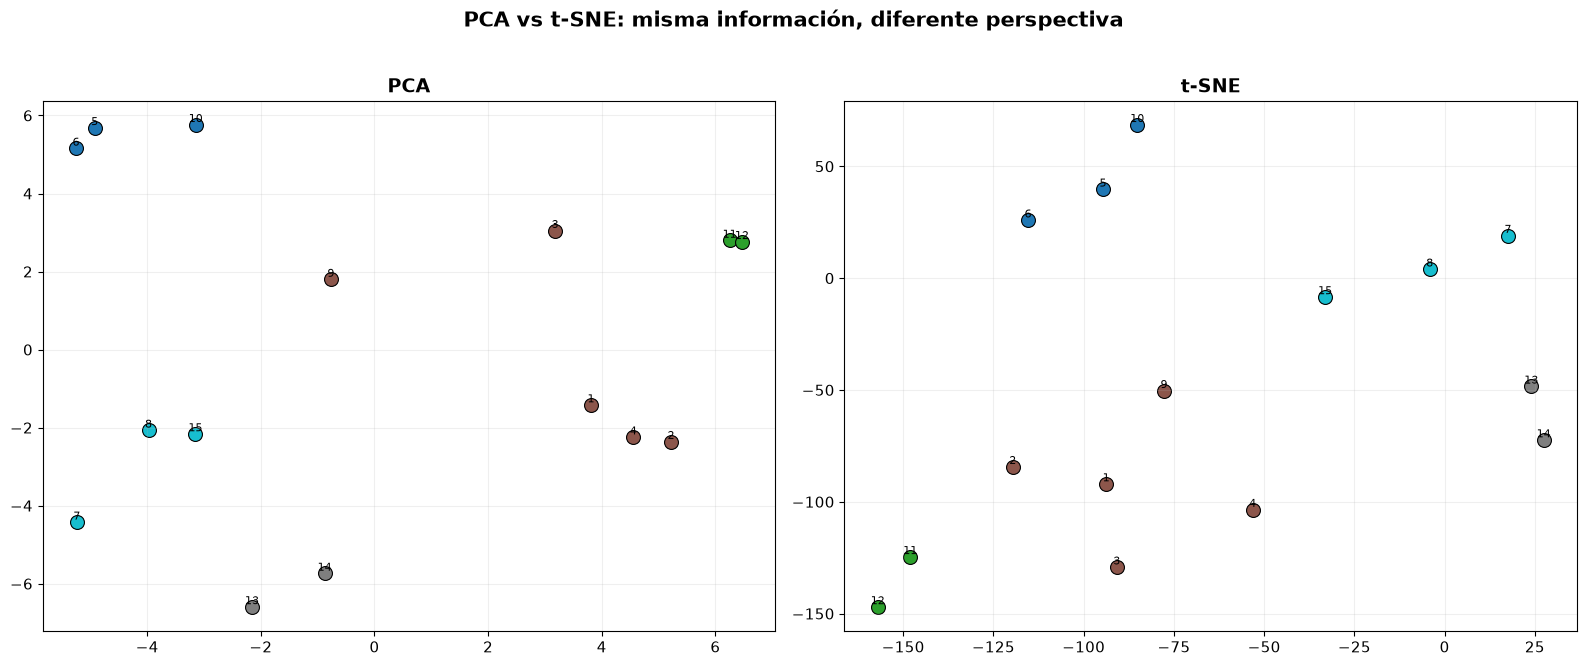


Observaciones:
  • PCA: preserva distancias globales. Buena para estructura general.
  • t‑SNE: agrupa vecinos cercanos. Excelente para revelar clusters.
  • Los colores corresponden a los clusters de K‑Means de la sección anterior.


In [16]:
if 'vecs_matrix' in dir():
    fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

    # PCA
    pca_viz = PCA(n_components=2, random_state=42)
    X_pca_viz = pca_viz.fit_transform(vecs_matrix)

    # t-SNE (con parámetros estables)
    print("Ejecutando t‑SNE (puede tardar unos segundos)...")
    tsne = TSNE(n_components=2, random_state=42, perplexity=5, max_iter=1000)
    X_tsne = tsne.fit_transform(vecs_matrix)

    for ax, X, title in zip(
        axes,
        [X_pca_viz, X_tsne],
        ['PCA', 't‑SNE']
    ):
        for i in range(len(corpus)):
            ax.scatter(X[i, 0], X[i, 1],
                       c=[cluster_colors[clusters[i]]],
                       s=100, edgecolors='black', linewidth=0.8)
            ax.annotate(str(i+1), (X[i, 0], X[i, 1]),
                        fontsize=8, ha='center', va='bottom')
        ax.set_title(f'{title}', fontweight='bold', fontsize=14)
        ax.grid(True, alpha=0.2)

    plt.suptitle('PCA vs t‑SNE: misma información, diferente perspectiva',
                 fontweight='bold', fontsize=15, y=1.02)
    plt.tight_layout()
    plt.show()

    print("\nObservaciones:")
    print("  • PCA: preserva distancias globales. Buena para estructura general.")
    print("  • t‑SNE: agrupa vecinos cercanos. Excelente para revelar clusters.")
    print("  • Los colores corresponden a los clusters de K‑Means de la sección anterior.")
else:
    print("No hay matriz de embeddings para comparar.")

---
## 13. Embeddings para frases cortas vs documentos largos

¿Qué pasa cuando comparamos una palabra con una frase? ¿Y una frase con un documento largo? Exploremos cómo se comportan los embeddings con textos de distinta longitud.

In [17]:
long_text = (
    "La inteligencia artificial ha revolucionado múltiples industrias en la última década. "
    "Desde la medicina hasta las finanzas, los algoritmos de aprendizaje automático están "
    "transformando la manera en que trabajamos y vivimos. Modelos como GPT, BERT y sus variantes "
    "han demostrado capacidades sorprendentes en comprensión y generación de lenguaje natural. "
    "El deep learning, una subárea del machine learning, utiliza redes neuronales artificiales "
    "con múltiples capas para extraer patrones complejos de grandes volúmenes de datos."
)

short_texts = [
    "IA",
    "inteligencia artificial",
    "machine learning",
    "deep learning",
    "redes neuronales",
    "algoritmos",
    "deportes de competición",   # distractor: tema no relacionado
]

print("Comparando similitud entre un texto largo y conceptos cortos...\n")
try:
    v_long = np.array(get_embedding(long_text, embed_model))
    print(f"Documento largo: {len(long_text)} caracteres\n")

    # Calcular similitudes y ordenar de mayor a menor
    resultados = []
    for st in short_texts:
        v_short = np.array(get_embedding(st, embed_model))
        sim = float(np.dot(v_long, v_short) / (
            np.linalg.norm(v_long) * np.linalg.norm(v_short) + 1e-9))
        resultados.append((st, sim))
    resultados.sort(key=lambda x: -x[1])

    print(f"{'#':<4} {'Concepto':<30} {'Similitud':>10}  Barra")
    print("-" * 70)
    for rank, (st, sim) in enumerate(resultados, 1):
        barra = '█' * int(max(sim, 0) * 30)
        print(f"{rank:<4} {st:<30} {sim:>10.4f}  {barra}")

    print("\n✓ Los conceptos relevantes (IA, deep learning, redes neuronales) encabezan")
    print("  el ranking, mientras el distractor ('deportes') queda al final.")
except Exception as e:
    print(f"Error: {e}")

Comparando similitud entre un texto largo y conceptos cortos...

Documento largo: 525 caracteres

#    Concepto                        Similitud  Barra
----------------------------------------------------------------------
1    deep learning                      0.5159  ███████████████
2    inteligencia artificial            0.4813  ██████████████
3    machine learning                   0.4643  █████████████
4    algoritmos                         0.4576  █████████████
5    redes neuronales                   0.3881  ███████████
6    IA                                 0.3018  █████████
7    deportes de competición            0.1677  █████

✓ Los conceptos relevantes (IA, deep learning, redes neuronales) encabezan
  el ranking, mientras el distractor ('deportes') queda al final.


---
## 14. Generando más embeddings para un análisis más rico

Creemos un conjunto más grande de frases sobre diversos temas para análisis avanzados.

In [18]:
frases_tematicas = [
    # Tecnología
    "El procesador ejecuta instrucciones a una velocidad de varios gigahercios.",
    "La memoria RAM almacena temporalmente los datos que el CPU necesita.",
    "Un algoritmo es una secuencia de pasos para resolver un problema.",
    "Python y JavaScript son lenguajes de programación muy populares en la actualidad.",
    "El código abierto permite a cualquiera inspeccionar, modificar y distribuir software.",
    # Naturaleza
    "Los bosques tropicales albergan una biodiversidad inmensa con miles de especies.",
    "El ciclo del agua describe cómo el agua se evapora, condensa y precipita continuamente.",
    "Las abejas son polinizadoras esenciales para la reproducción de muchas plantas.",
    "El cambio climático está alterando los patrones meteorológicos en todo el planeta.",
    "Los océanos cubren más del 70% de la superficie terrestre y regulan el clima.",
    # Música
    "La guitarra es un instrumento de cuerda pulsada con seis cuerdas normalmente.",
    "Beethoven compuso nueve sinfonías que revolucionaron la música clásica.",
    "El jazz nació en Nueva Orleans a principios del siglo XX como fusión de culturas.",
    "El rock and roll emergió en los años 50 con artistas como Elvis Presley y Chuck Berry.",
    "La música electrónica utiliza sintetizadores y cajas de ritmos para crear sonidos.",
    # Deportes
    "El baloncesto fue inventado por James Naismith en 1891 en Massachusetts.",
    "La natación es uno de los deportes más completos para el sistema cardiovascular.",
    "El maratón tiene una distancia oficial de 42.195 kilómetros desde 1921.",
    "Los Juegos Olímpicos modernos se celebraron por primera vez en Atenas en 1896.",
    "El ajedrez es considerado un deporte mental con millones de jugadores en el mundo.",
]

temas_labels = (["Tecnología"] * 5 + ["Naturaleza"] * 5 +
                ["Música"] * 5 + ["Deportes"] * 5)

print(f"Generando embeddings para {len(frases_tematicas)} frases...")
try:
    embeddings_tematicos = get_embeddings(frases_tematicas, model=embed_model)
    X_tematicos = np.array(embeddings_tematicos)
    print(f"✓ Matriz: {X_tematicos.shape[0]} frases × {X_tematicos.shape[1]} dimensiones")
except Exception as e:
    print(f"Error: {e}")
    X_tematicos = None

Generando embeddings para 20 frases...
  Procesados 5/20 textos...
  Procesados 10/20 textos...
  Procesados 15/20 textos...
  Procesados 20/20 textos...
✓ Matriz: 20 frases × 768 dimensiones


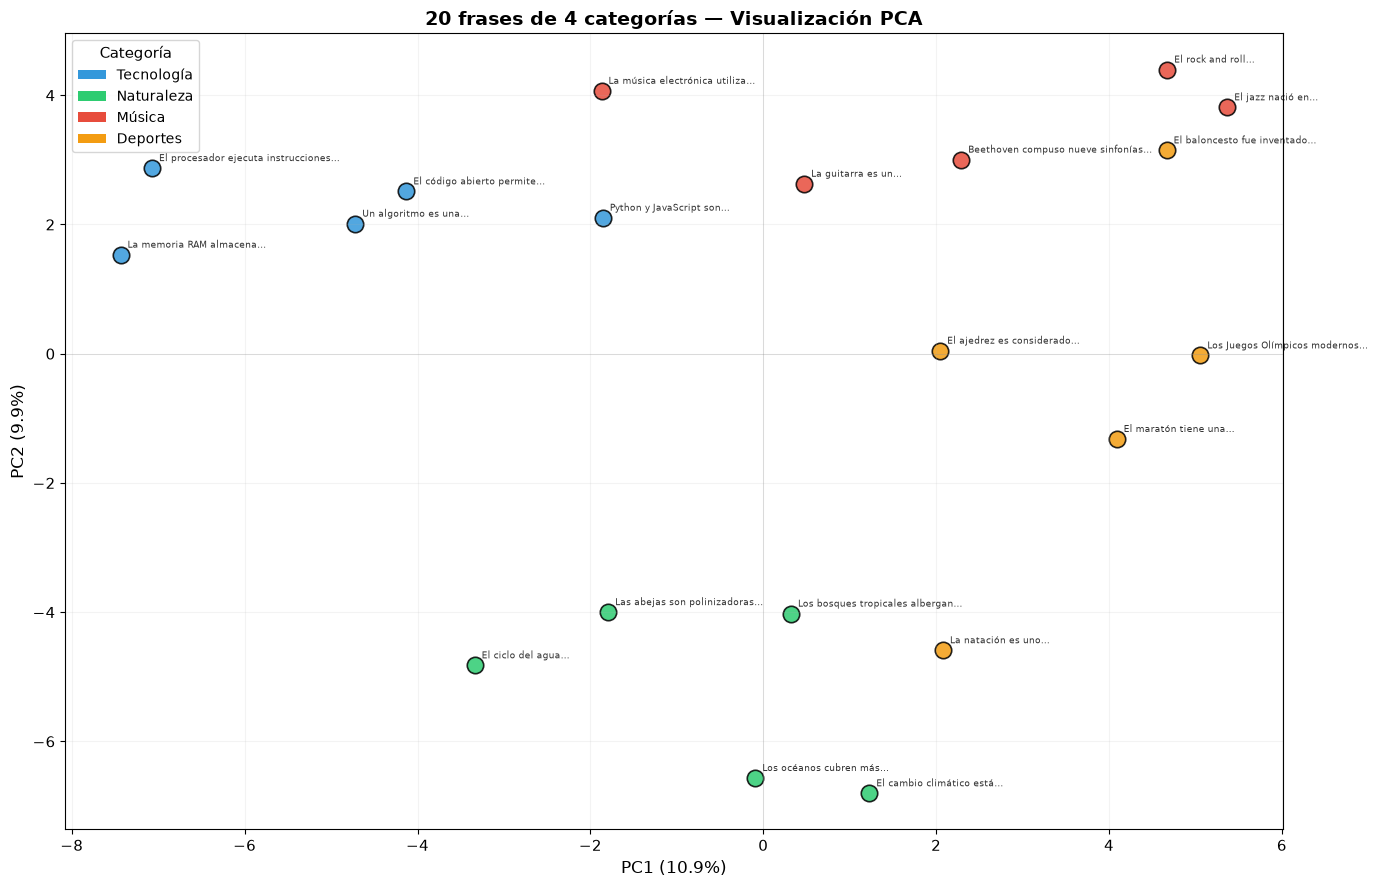

In [19]:
if X_tematicos is not None:
    pca = PCA(n_components=2, random_state=42)
    X_tem_2d = pca.fit_transform(X_tematicos)

    tema_colors = {
        "Tecnología": "#3498db",
        "Naturaleza": "#2ecc71",
        "Música": "#e74c3c",
        "Deportes": "#f39c12",
    }

    fig, ax = plt.subplots(figsize=(14, 9))
    for i in range(len(frases_tematicas)):
        tema = temas_labels[i]
        ax.scatter(X_tem_2d[i, 0], X_tem_2d[i, 1],
                   c=tema_colors[tema], s=140, edgecolors='black',
                   linewidth=1.2, alpha=0.85)
        # Etiqueta resumida
        short = ' '.join(frases_tematicas[i].split()[:4]) + '...'
        ax.annotate(short, (X_tem_2d[i, 0], X_tem_2d[i, 1]),
                    textcoords="offset points", xytext=(5, 5),
                    fontsize=6.5, alpha=0.8)

    ax.set_title('20 frases de 4 categorías — Visualización PCA',
                 fontweight='bold', fontsize=14)
    ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%})')
    ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%})')

    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor=v, label=k) for k, v in tema_colors.items()
    ]
    ax.legend(handles=legend_elements, loc='best', fontsize=10,
              title='Categoría')
    ax.grid(True, alpha=0.15)
    ax.axhline(0, color='gray', linewidth=0.5, alpha=0.3)
    ax.axvline(0, color='gray', linewidth=0.5, alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    print("No hay datos temáticos para visualizar.")

---
## 15. T‑SNE de las 4 categorías

t‑SNE revela clusters más compactos que PCA:

Ejecutando t‑SNE sobre las 20 frases...


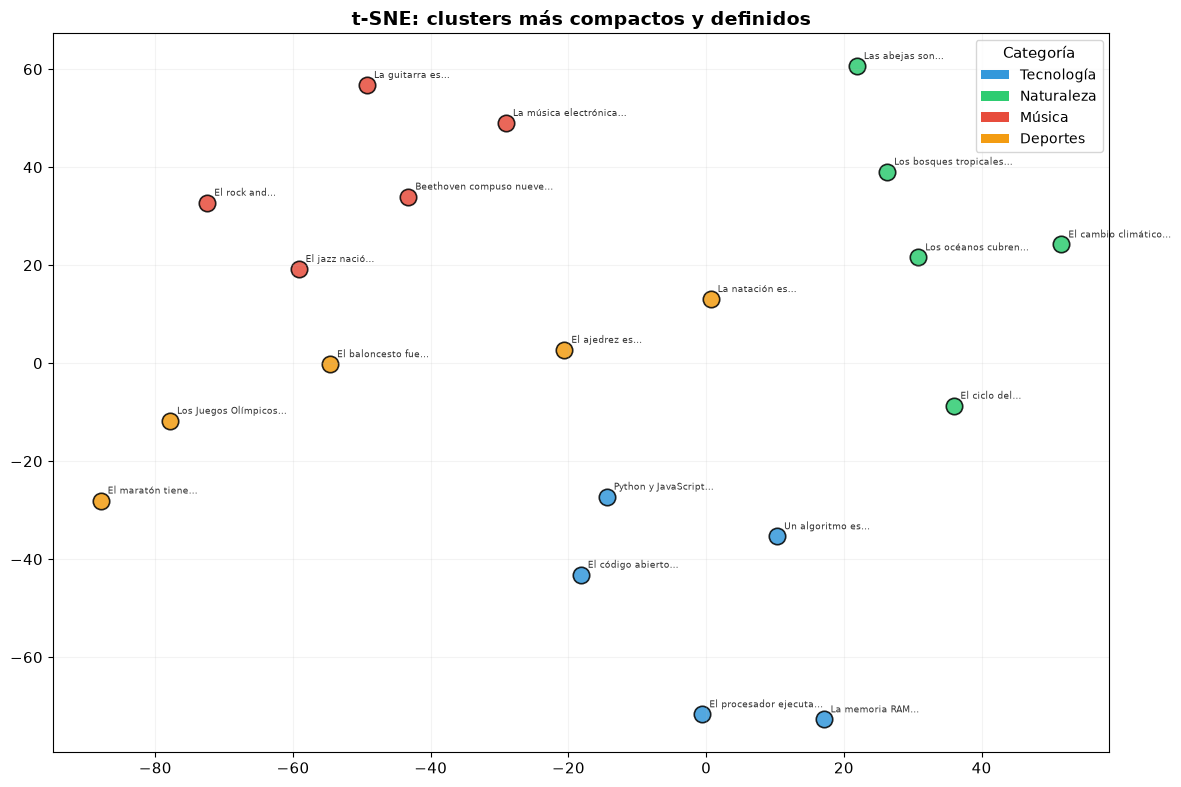

In [20]:
if X_tematicos is not None and X_tematicos.shape[0] >= 10:
    print("Ejecutando t‑SNE sobre las 20 frases...")
    tsne_tem = TSNE(n_components=2, random_state=42, perplexity=8, max_iter=1500)
    X_tem_tsne = tsne_tem.fit_transform(X_tematicos)

    fig, ax = plt.subplots(figsize=(12, 8))
    for i in range(len(frases_tematicas)):
        tema = temas_labels[i]
        ax.scatter(X_tem_tsne[i, 0], X_tem_tsne[i, 1],
                   c=tema_colors[tema], s=140, edgecolors='black',
                   linewidth=1.2, alpha=0.85)
        short = ' '.join(frases_tematicas[i].split()[:3]) + '...'
        ax.annotate(short, (X_tem_tsne[i, 0], X_tem_tsne[i, 1]),
                    textcoords="offset points", xytext=(5, 5),
                    fontsize=6.5, alpha=0.8)

    ax.set_title('t‑SNE: clusters más compactos y definidos',
                 fontweight='bold', fontsize=14)
    ax.grid(True, alpha=0.15)
    legend_elements = [
        Patch(facecolor=v, label=k) for k, v in tema_colors.items()
    ]
    ax.legend(handles=legend_elements, loc='best', fontsize=10,
              title='Categoría')
    plt.tight_layout()
    plt.show()
else:
    print("No hay suficientes datos para t‑SNE (mínimo 10 muestras).")

---
## 16. Aplicaciones reales de embeddings

Los embeddings son la base de prácticamente todos los sistemas modernos de NLP:

| Aplicación | Descripción | Ejemplo |
|------------|-------------|--------|
| **Búsqueda semántica** | Encontrar documentos por significado, no por palabras clave | Google, Elasticsearch |
| **RAG** (Retrieval-Augmented Generation) | Combinar búsqueda + generación para respuestas fundamentadas | Chatbots empresariales |
| **Sistemas de recomendación** | Recomendar contenido similar al que ya te gustó | Netflix, Spotify |
| **Clasificación de texto** | Asignar categorías usando la cercanía en el espacio semántico | Filtros de spam, análisis de sentimiento |
| **Detección de anomalías** | Identificar textos atípicos por su distancia a los clusters | Detección de fraude |
| **Traducción automática** | Alinear espacios semánticos de distintos idiomas | Google Translate |
| **Chatbots y asistentes** | Entender la intención del usuario mapeándola a vectores | Alexa, Siri, ChatGPT |
| **Deduplicación** | Encontrar textos casi idénticos aunque usen palabras diferentes | Limpieza de datos |

### El pipeline típico con embeddings

```
Documentos → Embeddings → [Búsqueda | Clustering | Clasificación | RAG]
                              ↓
                       Visualización (PCA / t‑SNE)
                              ↓
                       Interpretación humana
```

---
## 17. Resumen y conceptos clave

### Lo que aprendiste en esta clase

1. **Embedding** = vector denso que representa semánticamente un texto.
2. **Espacio semántico**: textos similares están cerca; la dirección codifica significado.
3. **Similitud del coseno** mide el ángulo entre vectores (la métrica estándar).
4. **Ollama** expone `/api/embeddings` para obtener vectores localmente.
5. **PCA** reduce dimensionalidad preservando varianza global.
6. **t‑SNE** revela estructura local y clusters finos.
7. **K‑Means** + embeddings = agrupación temática automática.
8. **Operaciones vectoriales** (analogías) capturan relaciones semánticas.
9. **Búsqueda semántica** encuentra documentos por significado, no por palabras.
10. Los embeddings son la **base** de RAG, recomendadores, clasificadores y más.

### Fórmulas importantes

$$
\begin{aligned}
\text{Similitud del coseno:} &\quad \cos(\vec{a}, \vec{b}) = \frac{\vec{a} \cdot \vec{b}}{\|\vec{a}\| \|\vec{b}\|} \\
\text{Analogías:} &\quad \vec{v}(\text{rey}) - \vec{v}(\text{hombre}) + \vec{v}(\text{mujer}) \approx \vec{v}(\text{reina}) \\
\text{PCA:} &\quad X_{reducido} = X \cdot W_{pca} \\
\end{aligned}
$$

### Para seguir aprendiendo

- **Documentación de Ollama**: https://github.com/ollama/ollama/blob/main/docs/api.md
- **Modelos de embeddings**: `nomic-embed-text`, `mxbai-embed-large`, `all-minilm`
- **Word2Vec paper** (Mikolov et al., 2013): origen de las analogías vectoriales
- **BERT paper** (Devlin et al., 2019): embeddings contextuales
- **Sentence Transformers**: embeddings de frases de alta calidad
- **FAISS / ChromaDB / Qdrant**: bases de datos vectoriales para producción

In [21]:
# Bonus: versión compacta demostrando todo el pipeline en una celda
print("=" * 55)
print("  RESUMEN DEMOSTRATIVO: separación semántica")
print("=" * 55)

mini_textos = [
    "perro", "canino",     # animales
    "python", "programación",  # tecnología
]

try:
    mini_vecs = get_embeddings(mini_textos, model=embed_model)
    sim_dentro = cosine_sim(mini_vecs[0], mini_vecs[1])    # perro-canino
    sim_cruzado = cosine_sim(mini_vecs[0], mini_vecs[2])   # perro-python
    print(f"\nSimilitud perro-canino (misma categoría):   {sim_dentro:.4f}")
    print(f"Similitud perro-python (categoría distinta): {sim_cruzado:.4f}")
    print(f"Margen de separación:                       {sim_dentro - sim_cruzado:.4f}")
    print(f"→ {sim_dentro > sim_cruzado}: conceptos de la misma categoría están")
    print(f"  más cerca que conceptos de categorías distintas.")
except Exception as e:
    print(f"Error: {e}")



  RESUMEN DEMOSTRATIVO: separación semántica

Similitud perro-canino (misma categoría):   0.6867
Similitud perro-python (categoría distinta): 0.3012
Margen de separación:                       0.3854
→ True: conceptos de la misma categoría están
  más cerca que conceptos de categorías distintas.
